# Polyp detection Kvasir-SEG + Yollo 11


## Download and explore dataset

In [23]:
!rm -f kvasir-seg.zip
!wget --no-check-certificate -q https://datasets.simula.no/downloads/kvasir-seg.zip
!unzip -q kvasir-seg.zip
!ls

^C
[kvasir-seg.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of kvasir-seg.zip or
        kvasir-seg.zip.zip, and cannot find kvasir-seg.zip.ZIP, period.
drive  Kvasir-SEG  kvasir-seg.zip  runs  sample_data  yolo11n.pt


In [2]:
!ls Kvasir-SEG
!ls Kvasir-SEG/images | head -5
!ls Kvasir-SEG/masks | head -5
!ls Kvasir-SEG/images | wc -l
!ls Kvasir-SEG/masks | wc -l

images	kavsir_bboxes.json  masks
cju0qkwl35piu0993l0dewei2.jpg
cju0qoxqj9q6s0835b43399p4.jpg
cju0qx73cjw570799j4n5cjze.jpg
cju0roawvklrq0799vmjorwfv.jpg
cju0rx1idathl0835detmsp84.jpg
cju0qkwl35piu0993l0dewei2.jpg
cju0qoxqj9q6s0835b43399p4.jpg
cju0qx73cjw570799j4n5cjze.jpg
cju0roawvklrq0799vmjorwfv.jpg
cju0rx1idathl0835detmsp84.jpg
1000
1000


In [3]:
import json

with open('Kvasir-SEG/kavsir_bboxes.json') as f:
    bboxes = json.load(f)

# look at one entry
sample_key = list(bboxes.keys())[0]
print(sample_key)
print(bboxes[sample_key])

cju0qkwl35piu0993l0dewei2
{'height': 529, 'width': 622, 'bbox': [{'label': 'polyp', 'xmin': 38, 'ymin': 5, 'xmax': 430, 'ymax': 338}]}


In [4]:
multi_box_count = sum(1 for v in bboxes.values() if len(v['bbox']) > 1)
print(f"Images with more than 1 polyp: {multi_box_count}")

resolutions = set((v['height'], v['width']) for v in bboxes.values())
print(f"Number of distinct resolutions: {len(resolutions)}")
print(list(resolutions)[:5])

Images with more than 1 polyp: 55
Number of distinct resolutions: 333
[(522, 621), (449, 469), (530, 561), (530, 570), (503, 616)]


## Convert Annotations to Yolo format

In [5]:
def convert_to_yolo(entry):
    height = entry['height']
    width = entry['width']

    lines = []
    for box in entry['bbox']:
        xmin, ymin = box['xmin'], box['ymin']
        xmax, ymax = box['xmax'], box['ymax']

        x_center = (xmin + xmax) / 2 / width
        y_center = (ymin + ymax) / 2 / height
        box_width = (xmax - xmin) / width
        box_height = (ymax - ymin) / height

        lines.append(f"0 {x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}")

    return lines

In [6]:
import os

labels_dir = 'Kvasir-SEG/labels'
os.makedirs(labels_dir, exist_ok=True)

for image_id, entry in bboxes.items():
    lines = convert_to_yolo(entry)
    label_path = os.path.join(labels_dir, f"{image_id}.txt")
    with open(label_path, 'w') as f:
        f.write('\n'.join(lines))

In [7]:
!ls Kvasir-SEG/labels | wc -l
!cat Kvasir-SEG/labels/cju0qkwl35piu0993l0dewei2.txt

1000
0 0.376206 0.324197 0.630225 0.629490

In [8]:
import random

image_ids = [f.replace('.jpg', '') for f in os.listdir('Kvasir-SEG/images')]

random.seed(42)
random.shuffle(image_ids)

n = len(image_ids)
train_end = int(0.70 * n)
val_end = train_end + int(0.15 * n)

train_ids = image_ids[:train_end]
val_ids = image_ids[train_end:val_end]
test_ids = image_ids[val_end:]

print(len(train_ids), len(val_ids), len(test_ids))

700 150 150


## Training , validation and test split

In [9]:
import shutil

def build_split(split_name, ids):
    img_dir = f'Kvasir-SEG/{split_name}/images'
    lbl_dir = f'Kvasir-SEG/{split_name}/labels'
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)

    for image_id in ids:
        shutil.copy(f'Kvasir-SEG/images/{image_id}.jpg', f'{img_dir}/{image_id}.jpg')
        shutil.copy(f'Kvasir-SEG/labels/{image_id}.txt', f'{lbl_dir}/{image_id}.txt')

build_split('train', train_ids)
build_split('val', val_ids)
build_split('test', test_ids)

print(len(os.listdir('Kvasir-SEG/train/images')))
print(len(os.listdir('Kvasir-SEG/val/images')))
print(len(os.listdir('Kvasir-SEG/test/images')))

700
150
150


In [10]:
yaml_content = """
path: /content/Kvasir-SEG
train: train/images
val: val/images
test: test/images

nc: 1
names: ['polyp']
"""

with open('Kvasir-SEG/data.yaml', 'w') as f:
    f.write(yaml_content)

print(yaml_content)


path: /content/Kvasir-SEG
train: train/images
val: val/images
test: test/images

nc: 1
names: ['polyp']



In [11]:
!pwd

/content


In [12]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.4/61.4 kB 5.7 MB/s eta 0:00:00


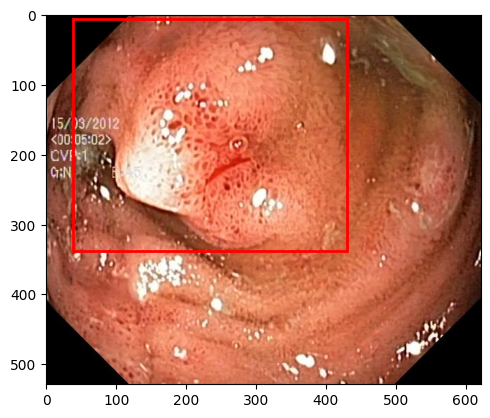

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

image_id = 'cju0qkwl35piu0993l0dewei2'
img = Image.open(f'Kvasir-SEG/images/{image_id}.jpg')

with open(f'Kvasir-SEG/labels/{image_id}.txt') as f:
    label_lines = f.readlines()

fig, ax = plt.subplots(1)
ax.imshow(img)

img_w, img_h = img.size

for line in label_lines:
    cls, x_center, y_center, w, h = map(float, line.split())

    box_x = (x_center - w / 2) * img_w
    box_y = (y_center - h / 2) * img_h
    box_w = w * img_w
    box_h = h * img_h

    rect = patches.Rectangle((box_x, box_y), box_w, box_h, linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

plt.show()

## Train Model

In [13]:
from ultralytics import YOLO

model = YOLO('yolo11n.pt')

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
import shutil
shutil.rmtree('kvasir_runs', ignore_errors=True)

!find / -iname "*.ttf" -path "*Ultralytics*" -delete 2>/dev/null
!find / -iname "Arial.ttf" -delete 2>/dev/null

In [ ]:
model = YOLO('yolo11n.pt')

results = model.train(
    data='Kvasir-SEG/data.yaml',
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project='kvasir_runs',
    name='baseline',
    plots=False
)

Ultralytics 8.4.118 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Kvasir-SEG/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline-2, nbs=64, nms=False, opset=None

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
shutil.copy(
    '/content/runs/detect/kvasir_runs/baseline-2/weights/best.pt',
    '/content/drive/MyDrive/kvasir_best.pt'
)

Mounted at /content/drive


'/content/drive/MyDrive/kvasir_best.pt'

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
from ultralytics import YOLO
model = YOLO('/content/drive/MyDrive/kvasir_best.pt')

## Evaluation on Test set

In [17]:
metrics = model.val(data='Kvasir-SEG/data.yaml', split='test')

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 987.9±284.4 MB/s, size: 34.5 KB)
val: Scanning /content/Kvasir-SEG/test/labels... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 1.5Kit/s 0.1s
val: New cache created: /content/Kvasir-SEG/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.9it/s 3.4s
                   all        150        160      0.949      0.929      0.971      0.848
Speed: 2.4ms preprocess, 5.2ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val


In [18]:
import random

sample_ids = random.sample(test_ids, 6)

results = model.predict(
    source=[f'Kvasir-SEG/test/images/{sid}.jpg' for sid in sample_ids],
    save=True,
    conf=0.5
)


0: 640x640 1 polyp, 5.1ms
1: 640x640 1 polyp, 5.1ms
2: 640x640 1 polyp, 5.1ms
3: 640x640 1 polyp, 5.1ms
4: 640x640 1 polyp, 5.1ms
5: 640x640 1 polyp, 5.1ms
Speed: 3.5ms preprocess, 5.1ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


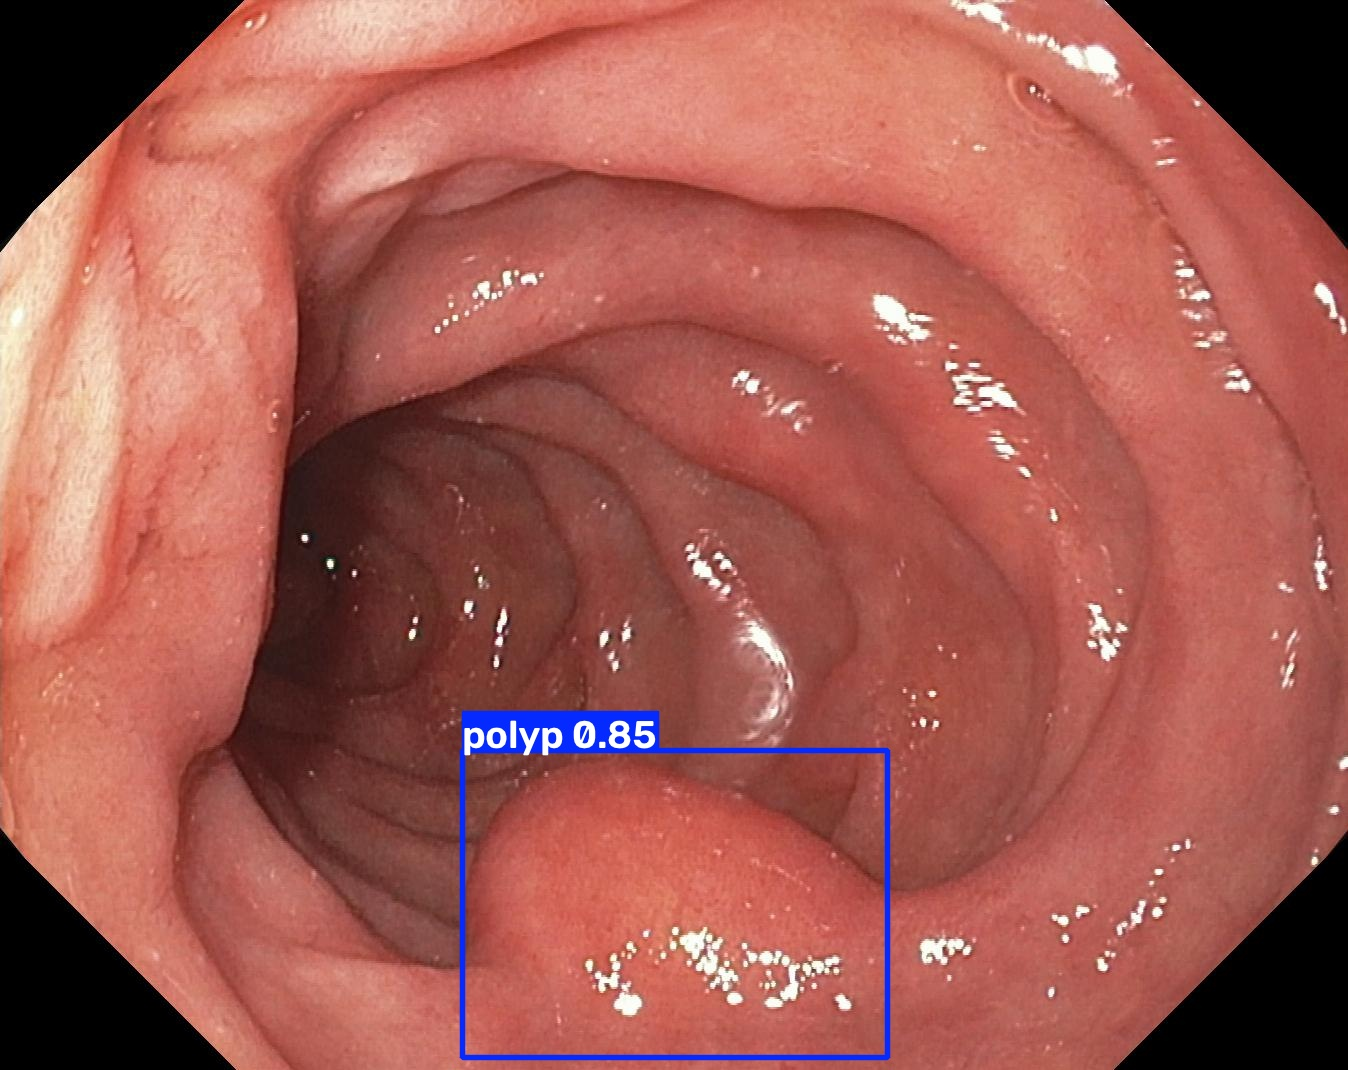

In [20]:
from PIL import Image as PILImage
import glob

predicted_images = glob.glob('runs/detect/predict/*.jpg')
PILImage.open(predicted_images[1])

In [22]:
import shutil
shutil.copytree('/content/runs/detect', '/content/drive/MyDrive/kvasir_runs_detect', dirs_exist_ok=True)

'/content/drive/MyDrive/kvasir_runs_detect'